# Credit Card Default Prediction – Machine Learning Project

**Objective:** Predict whether a customer will default on the next month's credit-card payment.

This notebook demonstrates a complete classification workflow:

1. Load libraries and dataset
2. Perform statistical analysis
3. Handle missing values and duplicates
4. Detect and cap outliers
5. Encode categorical features
6. Separate features (`X`) and target (`y`)
7. Visualize the data
8. Split data into training and testing sets
9. Apply feature selection and standardization
10. Train and evaluate four machine-learning algorithms

**Dataset note:** This notebook expects the UCI-style credit-card dataset saved as `creditcard.csv`. The loading section handles the extra header row found in some copies of this dataset.

## 1. Import required libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 2. Load the dataset

Update the file path if your CSV is stored in a different folder.

In [2]:
data = pd.read_csv("creditcard.csv")

print("Original dataset shape:", data.shape)
display(data.head())

Original dataset shape: (30001, 25)


,Unnamed: 0,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
0,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
1,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,Yes
2,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
3,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
4,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,NO


### 2.1 Correct the column headers (if required)

Some copies of this dataset contain the actual column names in the first data row and an extra unnamed index column. The following cell checks for that format and corrects it.

In [3]:
if "default payment next month" not in data.columns:
    data.columns = data.iloc[0].astype(str).str.strip()
    data = data.iloc[1:].reset_index(drop=True)

# Remove an unnecessary unnamed/index column, if present.
data = data.loc[:, ~data.columns.astype(str).str.contains(r"^Unnamed|^$", regex=True)]

# Convert columns to numeric values where possible.
for column in data.columns:
    data[column] = pd.to_numeric(data[column], errors="coerce")

df = data.copy()

print("Cleaned dataset shape:", df.shape)
print("Column names:")
print(df.columns.tolist())
display(df.head())

Cleaned dataset shape: (30000, 25)
Column names:
['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default payment next month']


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,NaN
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1.0
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0.0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,NaN
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0.0


## 3. Statistical analysis

In [4]:
print("Dataset information:")
df.info()

print("\nDescriptive statistics:")
display(df.describe().T)

print("\nTarget distribution:")
display(df["default payment next month"].value_counts(dropna=False))

print("\nTarget distribution (%):")
display(
    (df["default payment next month"].value_counts(normalize=True) * 100)
    .round(2)
)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  int64  
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  int64  
 13  BILL_AMT2            

,count,mean,std,min,25%,50%,75%,max
0,,,,,,,,
ID,30000.0,15000.500000,8660.398374,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0



Target distribution:


default payment next month
0.0    23363
1.0     6635
NaN        2
Name: count, dtype: int64


Target distribution (%):


default payment next month
0.0    77.88
1.0    22.12
Name: proportion, dtype: float64

## 4. Handle missing values

In [5]:
print("Missing values before treatment:")
display(df.isnull().sum().sort_values(ascending=False))

# The target cannot be imputed meaningfully for supervised learning.
df = df.dropna(subset=["default payment next month"]).copy()

# Fill missing numerical values with each column's median.
numeric_columns = df.select_dtypes(include="number").columns
for column in numeric_columns:
    if column != "default payment next month":
        df[column] = df[column].fillna(df[column].median())

print("\nMissing values after treatment:")
display(df.isnull().sum().sort_values(ascending=False))

Missing values before treatment:


0
default payment next month    2
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
ID                            0
PAY_3                         0
PAY_4                         0
PAY_6                         0
PAY_5                         0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT1                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT2                      0
PAY_AMT1                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
dtype: int64


Missing values after treatment:


0
ID                            0
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default payment next month    0
dtype: int64

## 5. Handle duplicate records

In [6]:
duplicate_count = df.duplicated().sum()
print("Number of duplicate rows:", duplicate_count)

df = df.drop_duplicates().reset_index(drop=True)

print("Dataset shape after removing duplicates:", df.shape)

Number of duplicate rows: 0
Dataset shape after removing duplicates: (29998, 25)


## 6. Detect and cap outliers using the IQR method

The function below caps outliers at the IQR lower and upper boundaries. It excludes the target and ID columns because the target is a class label and ID is an identifier, not a continuous measurement.

<Axes: xlabel='0'>

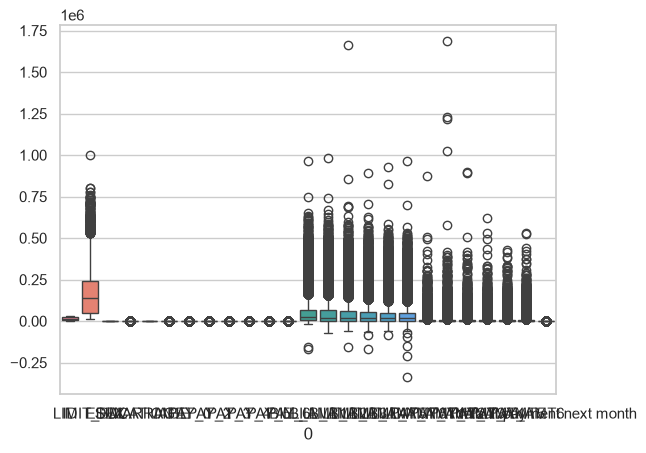

In [7]:
sns.boxplot(data= df)

In [8]:
def cap_outliers_iqr(dataframe, exclude_columns=None):
    dataframe = dataframe.copy()

    if exclude_columns is None:
        exclude_columns = []

    numeric_columns = dataframe.select_dtypes(include="number").columns

    for column in numeric_columns:
        if column in exclude_columns:
            continue

        q1 = dataframe[column].quantile(0.25)
        q3 = dataframe[column].quantile(0.75)
        iqr = q3 - q1

        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr

        dataframe[column] = dataframe[column].clip(
            lower=lower_bound,
            upper=upper_bound
        )

    return dataframe


df = cap_outliers_iqr(
    df,
    exclude_columns=["ID", "default payment next month"]
)

print("Outlier capping completed.")

Outlier capping completed.


### 6.1 Compare boxplots before and after capping

For readability, the plots below use selected numerical columns.

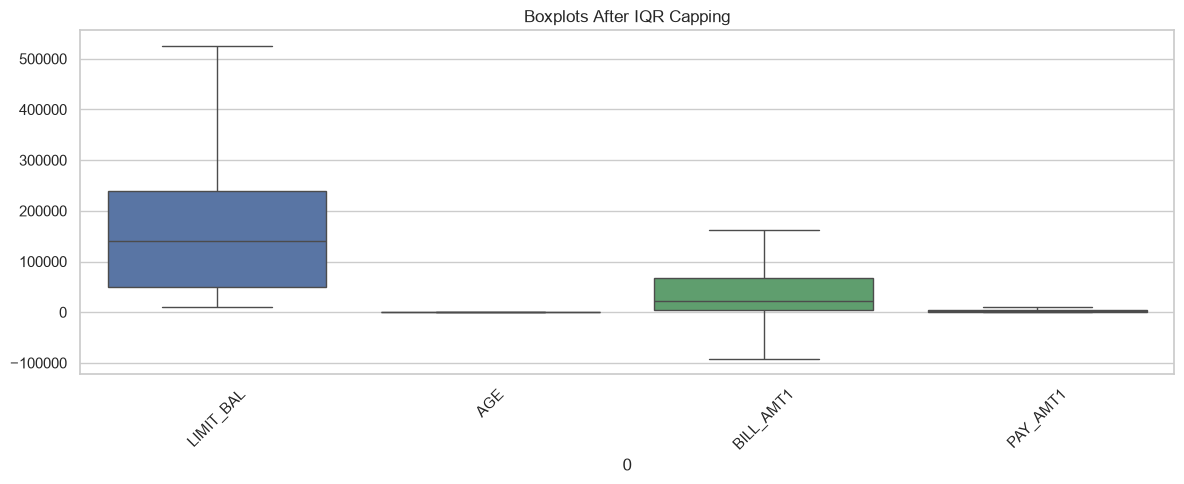

In [9]:
boxplot_columns = [
    column for column in ["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1"]
    if column in df.columns
]

plt.figure(figsize=(12, 5))
sns.boxplot(data=df[boxplot_columns])
plt.title("Boxplots After IQR Capping")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 7. Encode categorical features

The target column already contains binary class values (0 and 1), so it does not need Label Encoding.

The categorical predictor columns are handled with OneHotEncoder inside the preprocessing pipeline. This ensures that encoding is learned from the training data only.

In [10]:
target_column = "default payment next month"

# Categorical columns represented by numeric category codes in this dataset.
categorical_columns = [
    column for column in ["SEX", "EDUCATION", "MARRIAGE"]
    if column in df.columns
]

print("Categorical predictor columns:", categorical_columns)

Categorical predictor columns: ['SEX', 'EDUCATION', 'MARRIAGE']


## 8. Separate independent variables (X) and dependent variable (y)

In [11]:
# ID is an identifier, so it is excluded from the predictors.
X = df.drop(
    columns=[target_column, "ID"],
    errors="ignore"
)

y = df[target_column].astype(int)

print("Independent variables (X):", X.shape)
print("Dependent variable (y):", y.shape)

print("\nTarget classes:")
print(y.value_counts())

Independent variables (X): (29998, 23)
Dependent variable (y): (29998,)

Target classes:
default payment next month
0    23363
1     6635
Name: count, dtype: int64


## 9. Rename columns (optional)

In [12]:
# Rename the target and PAY_0 column for easier reference.
df = df.rename(columns={
    "default payment next month": "default_payment_next_month",
    "PAY_0": "PAY_1"
})

X = X.rename(columns={"PAY_0": "PAY_1"})
y.name = "default_payment_next_month"

print("Updated column names:")
print(df.columns.tolist())

Updated column names:
['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_1', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default_payment_next_month']


## 10. Data visualization

The following six visualizations help explore the target distribution, customer age, credit limit, and relationships between selected variables.

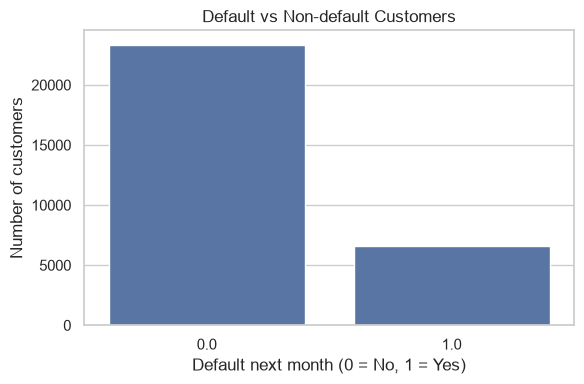

In [14]:
# Visualization 1: Target class distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="default_payment_next_month")
plt.title("Default vs Non-default Customers")
plt.xlabel("Default next month (0 = No, 1 = Yes)")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()



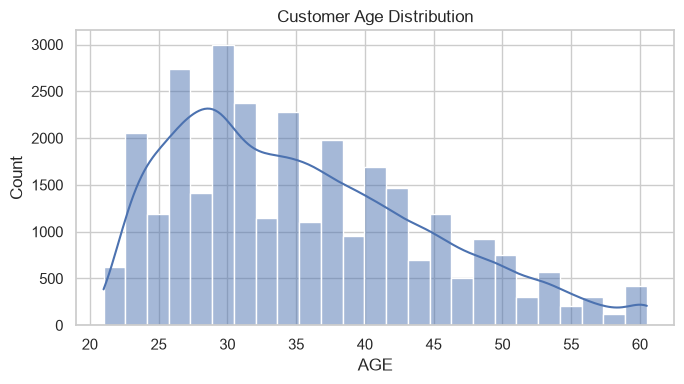

In [15]:
# Visualization 2: Customer age distribution
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="AGE", bins=25, kde=True)
plt.title("Customer Age Distribution")
plt.tight_layout()
plt.show()



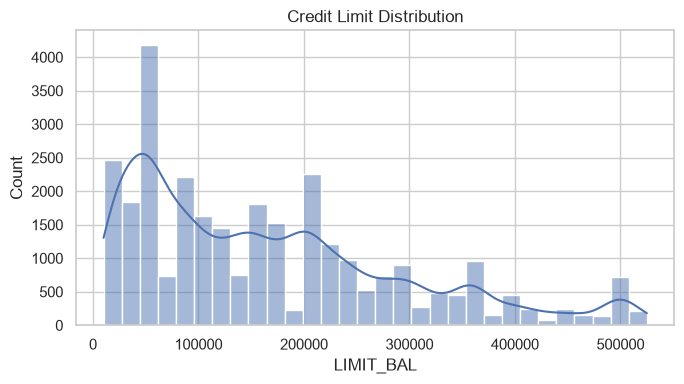

In [16]:
# Visualization 3: Credit limit distribution
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="LIMIT_BAL", bins=30, kde=True)
plt.title("Credit Limit Distribution")
plt.tight_layout()
plt.show()



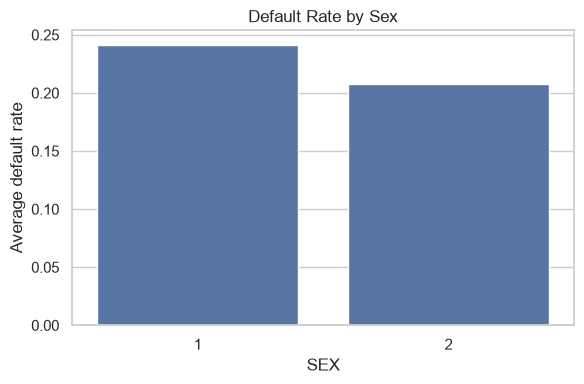

In [17]:
# Visualization 4: Default rate by sex
plt.figure(figsize=(6, 4))
sns.barplot(
    data=df,
    x="SEX",
    y="default_payment_next_month",
    errorbar=None
)
plt.title("Default Rate by Sex")
plt.ylabel("Average default rate")
plt.tight_layout()
plt.show()



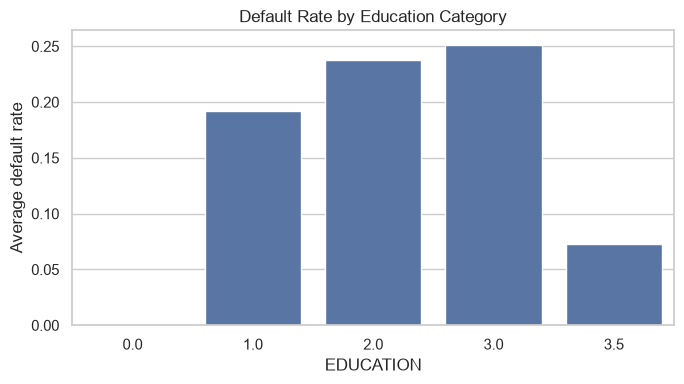

In [18]:
# Visualization 5: Default rate by education category
plt.figure(figsize=(7, 4))
sns.barplot(
    data=df,
    x="EDUCATION",
    y="default_payment_next_month",
    errorbar=None
)
plt.title("Default Rate by Education Category")
plt.ylabel("Average default rate")
plt.tight_layout()
plt.show()



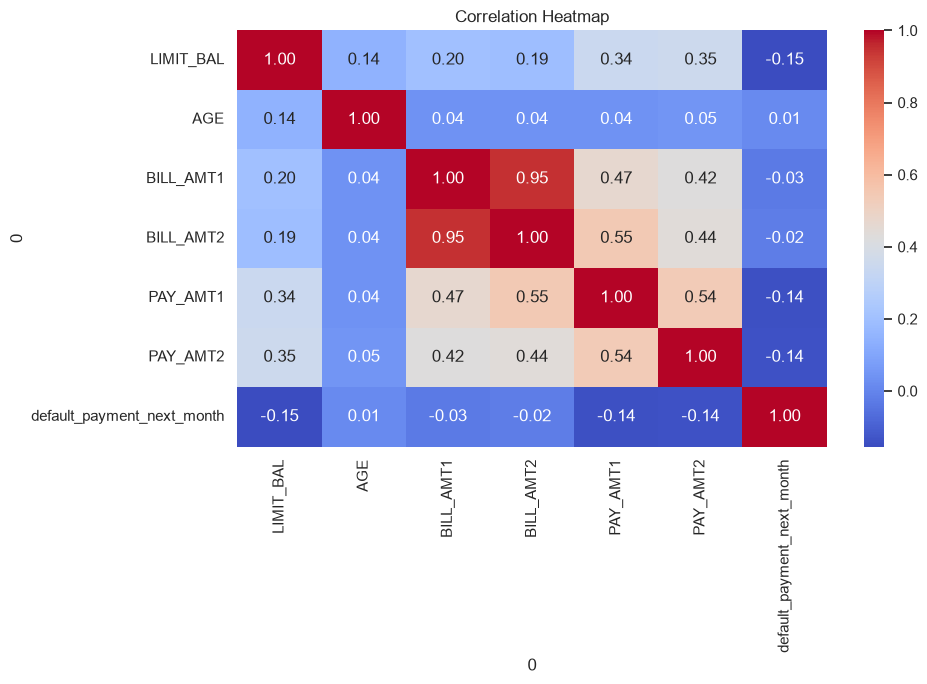

In [19]:
# Visualization 6: Correlation heatmap
correlation_columns = [
    "LIMIT_BAL", "AGE", "BILL_AMT1", "BILL_AMT2",
    "PAY_AMT1", "PAY_AMT2", "default_payment_next_month"
]
correlation_columns = [
    column for column in correlation_columns if column in df.columns
]

plt.figure(figsize=(10, 7))
sns.heatmap(
    df[correlation_columns].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## 11. Train-test split

Split the data before fitting the encoder, scaler, or feature-selection method. This prevents information from the test data leaking into the training process.

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))
print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training features: (23998, 23)
Testing features: (6000, 23)

Training target distribution:
default_payment_next_month
0    0.779
1    0.221
Name: proportion, dtype: float64

Testing target distribution:
default_payment_next_month
0    0.779
1    0.221
Name: proportion, dtype: float64


## 12. Preprocessing: One-Hot Encoding and StandardScaler

- Numerical columns: missing-value imputation using the median, followed by StandardScaler.
- Categorical columns: most-frequent imputation, followed by OneHotEncoder.

`fit` is performed only on the training data. The fitted transformations are then applied to the test data.

In [21]:
numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = [
    column for column in categorical_columns if column in X_train.columns
]

# Remove categorical columns from the numerical feature list.
numeric_features = [
    column for column in numeric_features
    if column not in categorical_features
]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['LIMIT_BAL', 'AGE', 'PAY_1', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']
Categorical features: ['SEX', 'EDUCATION', 'MARRIAGE']


## 13. Feature selection using SelectKBest

`SelectKBest` selects the K features with the highest statistical scores.

- `f_classif` is suitable for classification.
- `k=20` selects the 20 highest-scoring transformed features.
- Feature selection is placed inside the model pipeline so it is fitted using training data only.

In [28]:
selector = SelectKBest(score_func=f_classif, k=20)

X_new = selector.fit_transform(X, y)

In [29]:
selected_features = X.columns[selector.get_support()]

print("Selected Features:")
print(selected_features)

Selected Features:
Index(['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'PAY_1', 'PAY_2', 'PAY_3',
       'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3',
       'BILL_AMT4', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5',
       'PAY_AMT6'],
      dtype='str', name=0)


In [30]:
feature_scores = pd.DataFrame({
    'Feature': X.columns,
    'Score': selector.scores_,
    'Selected': selector.get_support()
})

feature_scores = feature_scores.sort_values(
    by='Score',
    ascending=False
)

print(feature_scores)

      Feature        Score  Selected
5       PAY_1  2787.906363      True
6       PAY_2  1756.487630      True
7       PAY_3  1365.640530      True
8       PAY_4  1087.228198      True
9       PAY_5   923.679087      True
10      PAY_6   755.343551      True
0   LIMIT_BAL   731.959868      True
17   PAY_AMT1   629.766675      True
18   PAY_AMT2   596.778241      True
19   PAY_AMT3   472.450244      True
22   PAY_AMT6   398.600837      True
20   PAY_AMT4   392.700506      True
21   PAY_AMT5   354.287809      True
1         SEX    48.071168      True
2   EDUCATION    47.795070      True
11  BILL_AMT1    25.221326      True
3    MARRIAGE    17.714502      True
12  BILL_AMT2    15.507631      True
13  BILL_AMT3    13.113582      True
14  BILL_AMT4     8.065532      True
4         AGE     5.688377     False
15  BILL_AMT5     5.404308     False
16  BILL_AMT6     2.320739     False


In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)
print("\nTraining target proportions:")
print(y_train.value_counts(normalize=True).round(3))
print("\nTesting target proportions:")
print(y_test.value_counts(normalize=True).round(3))

Training set: (23998, 23)
Testing set: (6000, 23)

Training target proportions:
default_payment_next_month
0    0.779
1    0.221
Name: proportion, dtype: float64

Testing target proportions:
default_payment_next_month
0    0.779
1    0.221
Name: proportion, dtype: float64


In [32]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

## 14. Build and train classification models

Four algorithms are compared:

1. Logistic Regression
2. Decision Tree
3. Random Forest

Each model uses the same preprocessing and feature-selection steps for a fair comparison.

In [33]:
# Selecting Algorithm 
models = {
    "Logistic Regression": LogisticRegression(),
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(n_estimators=100),
}


In [37]:
from sklearn.metrics import precision_score, f1_score, recall_score
#Store results
scores = []
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracy= accuracy_score(y_test,y_pred)
    precision= precision_score(y_test,y_pred)
    f1= f1_score(y_test,y_pred)
    recall= recall_score(y_test,y_pred)
    scores.append({
        "Model": name,
        "accuracy": round(accuracy, 2),
        "precision": round(precision, 2),
        "f1": round(f1, 2),
        "recall": round(recall, 2)
    })
# Convert to DataFrame for nice display
results_df = pd.DataFrame(scores)
print(results_df)

                 Model  accuracy  precision    f1  recall
0  Logistic Regression      0.78       0.62  0.03    0.02
1        Decision Tree      0.73       0.39  0.40    0.41
2        Random Forest      0.82       0.64  0.48    0.39


## Conclusion

- Compare the four algorithms using Accuracy, Precision, Recall, F1-score, and ROC-AUC.
- For identifying customers who may default, pay particular attention to **Recall for class 1**.
- Review the confusion matrix to understand false positives and false negatives.
- The best model in this notebook is selected using the F1-score; a different metric may be more appropriate depending on the business objective.

**Important:** This is an educational project. A model should not be used for real credit decisions without appropriate fairness, privacy, explainability, regulatory, and independent validation checks.